RQ1 human comparison: is the pin on a roof?

Sample: `draw_subsample(main, "human_comparison")`, one random primary-bin pin per source (±1 m excluded).
Image = the same render the models get (full 512 px crop, `google_pin_red` at the tip). Answer from the image only.
No bin or distance is shown. Log: `gold/human_on_roof.jsonl`.

In [3]:
%env DYLD_FALLBACK_LIBRARY_PATH=/opt/homebrew/lib

import json

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from rasterio.windows import Window

from thesis.data import naip
from thesis.eval.subsamples import draw_subsample, one_pin_per_source
from thesis.render.marker import render_at_tip
from thesis.render.presets import load_presets
from thesis.run import REPO_ROOT, _geometry_to_crs, load_config

out_dir = REPO_ROOT / "data" / "dataset_v2"
imagery_config = load_config("imagery")
scene_cache = REPO_ROOT / imagery_config["scene_cache_dir"]
preset = load_presets(load_config("render"))["google_pin_red"]
PRIMARY_BINS = load_config("scoring")["primary_bins"]
ANNOTATOR = "phillip"

env: DYLD_FALLBACK_LIBRARY_PATH=/opt/homebrew/lib


In [4]:
selected = pd.read_parquet(out_dir / "selection" / "sources.parquet")
pins = pd.read_parquet(out_dir / "audit" / "selected_pins.parquet")
boxes = gpd.read_parquet(out_dir / "inventory" / "boxes.parquet")
box_geometries = boxes.set_index("box_id").geometry.to_dict()

# run the late-removal cell in gold_dataset_filtering.ipynb first, so the gold file is final
gold = selected.merge(pd.read_json(out_dir / "gold" / "is_building.jsonl", lines=True), on="source_id")
main = gold.loc[gold["is_building"] & (gold["assignment"] == "main")].set_index("source_id", drop=False)

sample_sources = draw_subsample(main, "human_comparison")
sample = (
    one_pin_per_source(pins.loc[pins["bin_id"].isin(PRIMARY_BINS)], sample_sources, "human_comparison")
    .merge(
        sample_sources[["source_id", "box_id", "naip_item_id", "scene_window"]].reset_index(drop=True), on="source_id"
    )
    .sample(frac=1, random_state=0)  # shuffle so bins and boxes are interleaved
    .reset_index(drop=True)
)
len(main), len(sample), sample["box_id"].nunique(), sample["bin_id"].value_counts().sort_index().to_dict()

(1849, 197, 99, {-5: 18, -3: 30, 3: 27, 5: 26, 10: 20, 20: 28, 40: 23, 80: 25})

In [5]:
# same crop loading as gold_dataset_filtering
item_records: dict[str, dict[str, dict]] = {}


def get_item(box_id: str, naip_item_id: str) -> dict:
    if box_id not in item_records:
        box_wgs84 = _geometry_to_crs(box_geometries[box_id], "EPSG:5070", "EPSG:4326")
        item_records[box_id] = {
            str(item["id"]): item for item in naip.search_items_for_geometry(box_wgs84, imagery_config)
        }
    return item_records[box_id][str(naip_item_id)]


def raw_crop_for(row) -> np.ndarray:
    item = get_item(str(row["box_id"]), row["naip_item_id"])
    scene_window = Window(*[int(v) for v in row["scene_window"]])
    cache_key = naip.window_cache_key(str(row["naip_item_id"]), scene_window)
    tile = naip.load_cached(scene_cache, cache_key)
    if tile is None:
        tile = naip.read_item_window(
            item, scene_window, float(imagery_config["gsd_m"]), float(imagery_config["gsd_tolerance"])
        )
        naip.store_atomic(scene_cache, cache_key, tile.array, tile.metadata)
    col_off, row_off, width, height = [int(v) for v in row["crop_window"]]
    return tile.array[:, row_off : row_off + height, col_off : col_off + width]


def display_render(crop: np.ndarray) -> None:
    rendered = render_at_tip(crop, preset)
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(np.transpose(rendered, (1, 2, 0)))
    ax.axis("off")
    display(fig)
    plt.close(fig)

In [6]:
log_path = out_dir / "gold" / "human_on_roof.jsonl"
done = set()
if log_path.exists():
    done = {json.loads(line)["pin_id"] for line in log_path.read_text().splitlines()}
remaining = sample.loc[~sample["pin_id"].isin(done)].reset_index(drop=True)
i = 0
len(remaining)

0

In [ ]:
# run repeatedly
row = remaining.iloc[i]
display_render(raw_crop_for(row))
print(f"[{i + 1}/{len(remaining)}]")

call = input("pin on a roof? (y/n): ").strip().lower()
with log_path.open("a") as f:
    f.write(
        json.dumps(
            {
                "pin_id": row["pin_id"],
                "source_id": row["source_id"],
                "annotator": ANNOTATOR,
                "parsed_answer": "yes" if call.startswith("y") else "no",
                "raw": call,
            }
        )
        + "\n"
    )
i += 1

In [8]:
# quick look only; the RQ1 comparison runs through thesis.eval.scorer with model = "human"
answers = pd.read_json(log_path, lines=True).merge(pins[["pin_id", "bin_id"]], on="pin_id")
answers["inside"] = answers["bin_id"] < 0
answers["correct"] = (answers["parsed_answer"] == "yes") == answers["inside"]
len(answers), answers["correct"].mean(), answers.groupby("bin_id")["correct"].mean()

(197,
 np.float64(0.9289340101522843),
 bin_id
 -5     1.000000
 -3     0.866667
  3     0.777778
  5     1.000000
  10    1.000000
  20    0.928571
  40    0.913043
  80    1.000000
 Name: correct, dtype: float64)

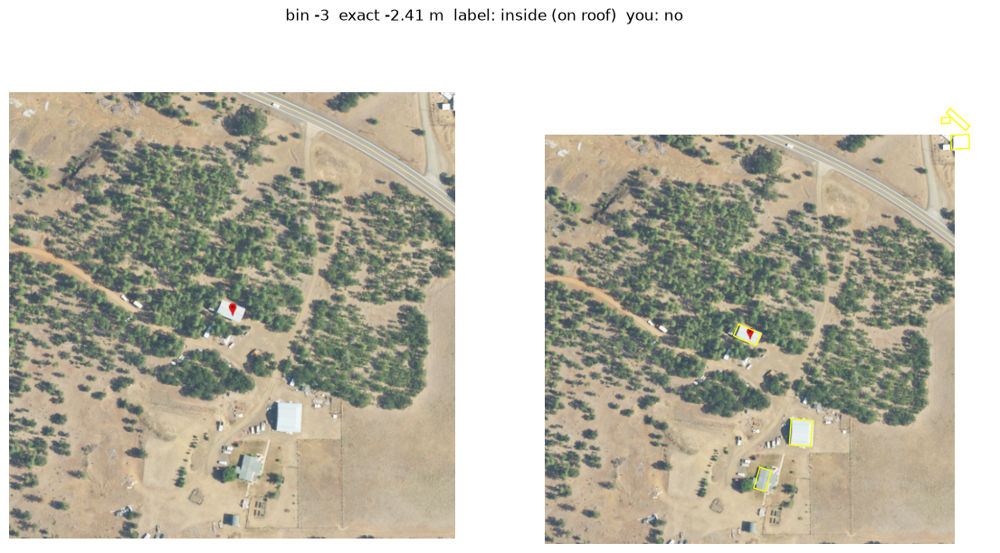

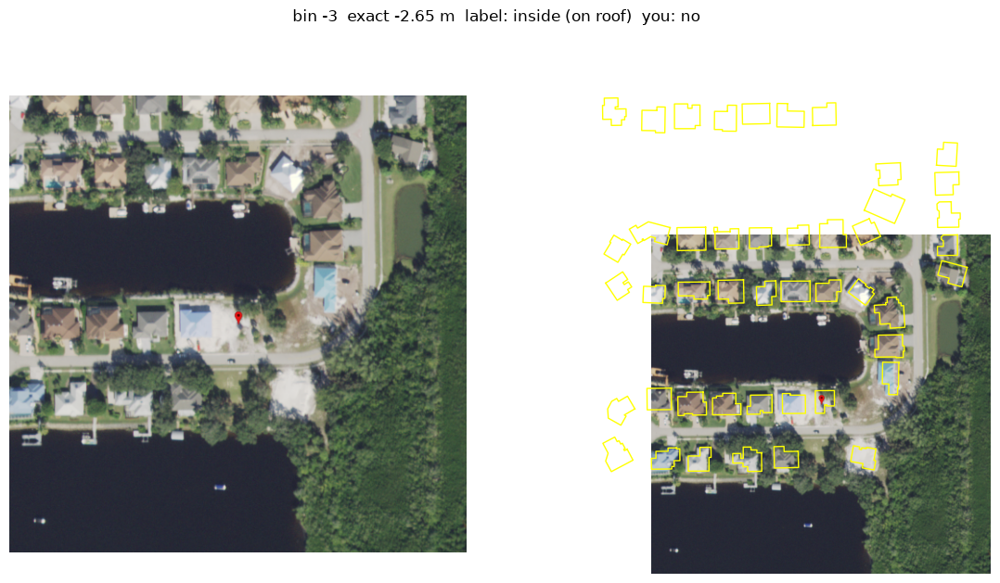

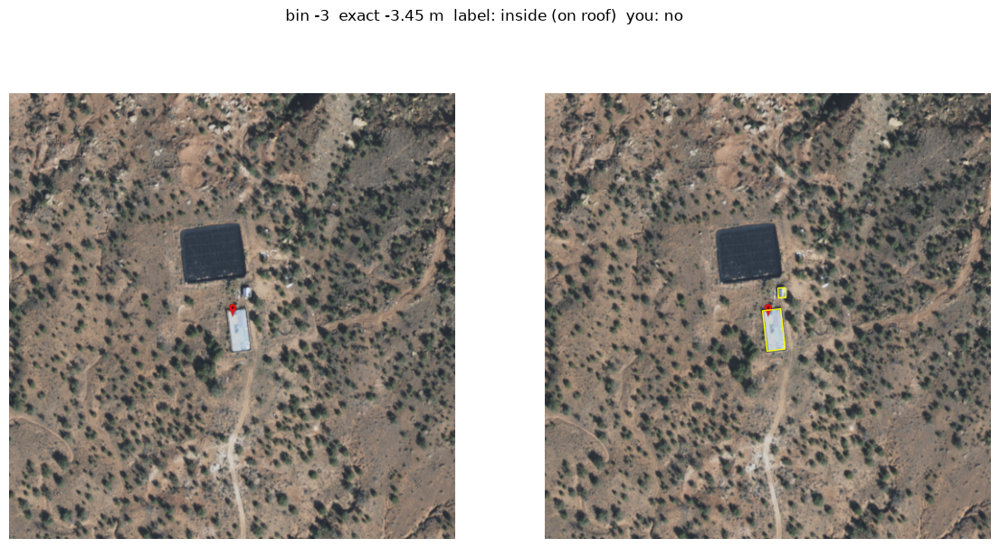

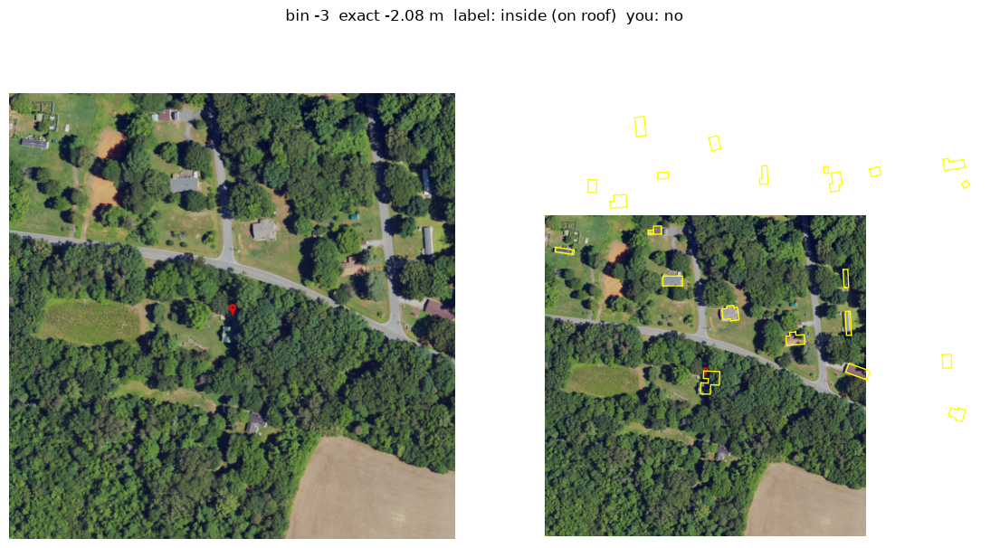

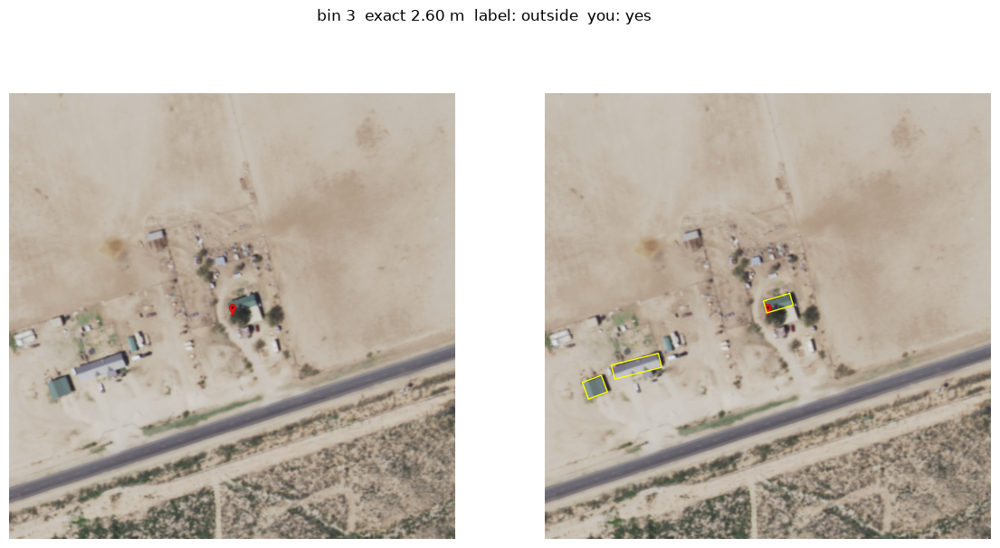

...

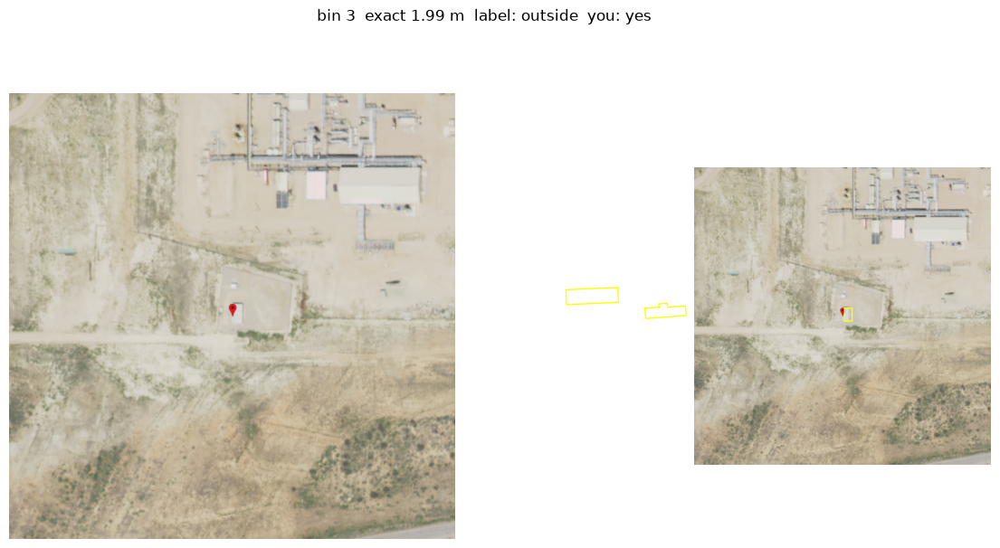

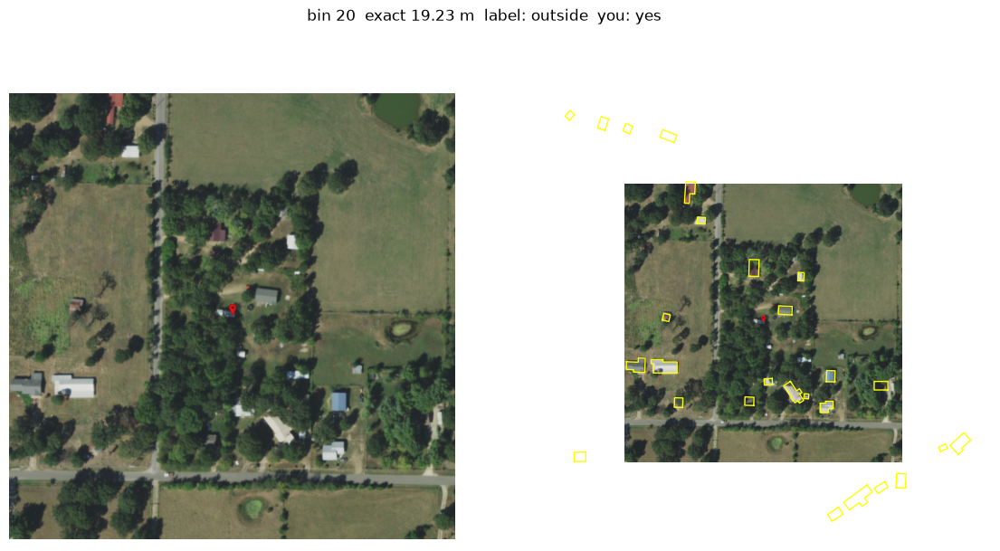

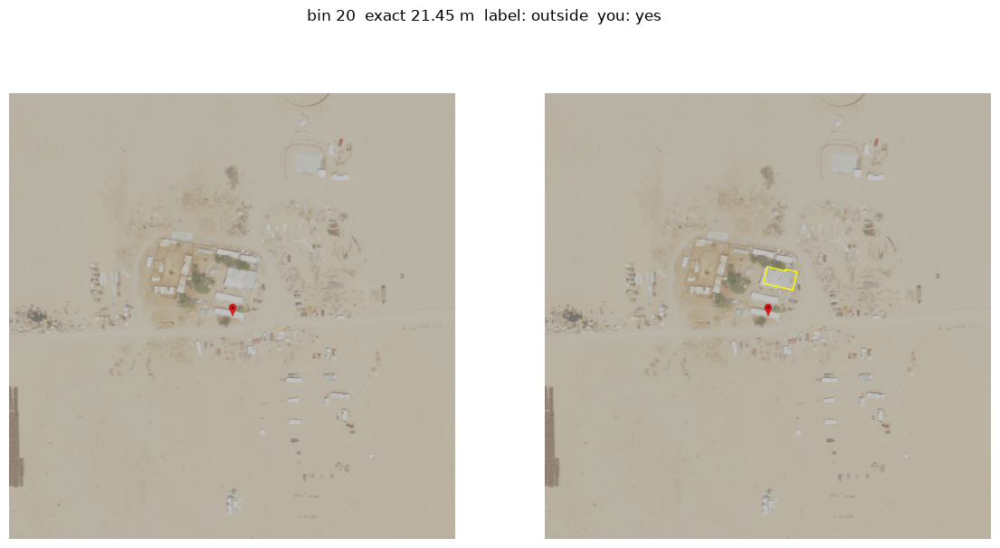

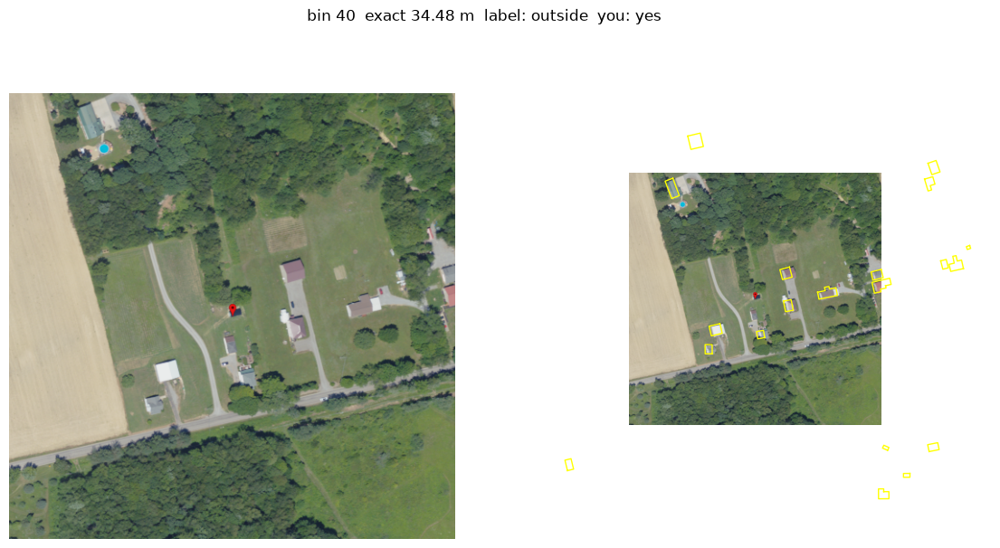

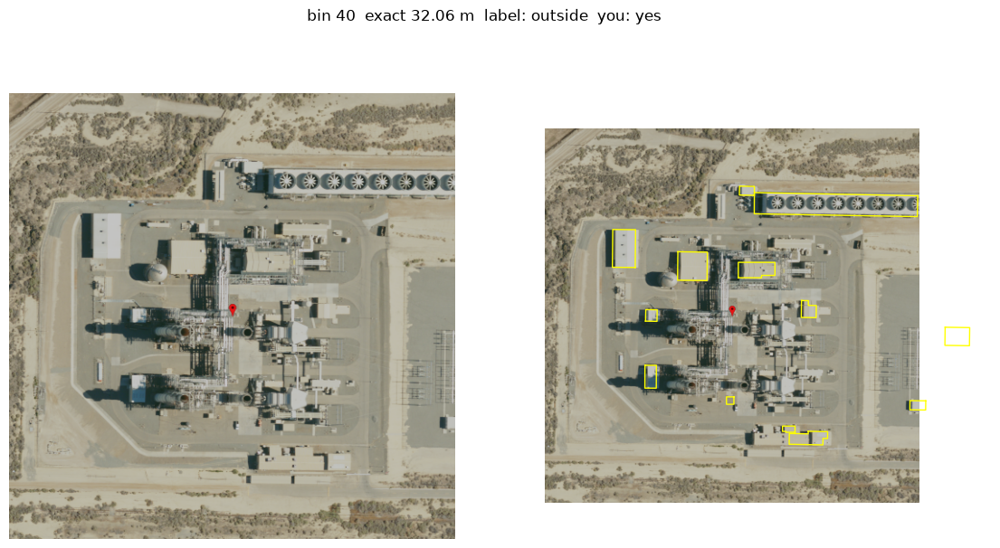

In [10]:
# all errores
from affine import Affine
from shapely import from_wkb

from thesis.data.eligibility import context_for_scene
from thesis.run import _valid_context_footprints

footprints = _valid_context_footprints(gpd.read_parquet(REPO_ROOT / load_config("overture")["out"]))
errors = (
    answers.loc[~answers["correct"], ["pin_id", "parsed_answer"]]
    .merge(sample, on="pin_id")
    .merge(selected[["source_id", "naip_source_crs", "scene_geometry_wkb"]], on="source_id")
    .sort_values("bin_id")
)
for _, row in errors.iterrows():
    rendered = render_at_tip(raw_crop_for(row), preset)
    scene_wgs84 = _geometry_to_crs(from_wkb(row["scene_geometry_wkb"]), "EPSG:5070", "EPSG:4326")
    scene_footprints = context_for_scene(footprints, scene_wgs84).to_crs(str(row["naip_source_crs"]))
    to_px = ~Affine(*row["crop_transform"])

    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    for ax in axes:
        ax.imshow(np.transpose(rendered, (1, 2, 0)))
        ax.axis("off")
    for geometry in scene_footprints.geometry:
        for polygon in getattr(geometry, "geoms", [geometry]):
            cols, rows = zip(*[to_px * xy for xy in polygon.exterior.coords])
            axes[1].plot(np.array(cols) - 0.5, np.array(rows) - 0.5, color="yellow", linewidth=1)
    label = "inside (on roof)" if row["bin_id"] < 0 else "outside"
    fig.suptitle(
        f"bin {row['bin_id']}  exact {row['exact_signed_distance_m']:.2f} m  label: {label}  you: {row['parsed_answer']}"
    )
    display(fig)
    plt.close(fig)

In [ ]:
# post-hoc review of my 14 disagreements (2026-10-05), in the display order above. Run in the same kernel as the review cell.
# answers are NOT corrected: the human baseline stays the blind first pass.
REVIEW = [
    "my_error",
    "demolished",
    "my_error",
    "tree_occlusion",
    "my_error",
    "footprint_offset",
    "footprint_offset",
    "my_error",
    "footprint_offset",
    "my_error",
    "unmapped_outbuilding",
    "unmapped_outbuilding",
    "unmapped_outbuilding",
    "my_error",
]
assert len(REVIEW) == len(errors)
review = errors[["pin_id", "bin_id", "exact_signed_distance_m", "parsed_answer"]].assign(cause=REVIEW)
review.to_json(out_dir / "gold" / "human_error_review.jsonl", orient="records", lines=True)
review.groupby("cause").size(), review.groupby(["bin_id", "cause"]).size()

(cause
 demolished              1
 footprint_offset        3
 my_error                6
 tree_occlusion          1
 unmapped_outbuilding    3
 dtype: int64,
 bin_id  cause               
 -3      demolished              1
         my_error                2
         tree_occlusion          1
  3      footprint_offset        3
         my_error                3
  20     unmapped_outbuilding    2
  40     my_error                1
         unmapped_outbuilding    1
 dtype: int64)